# 05 — Máximas anuais acumuladas das séries observada e simuladas

Este notebook lê as **nove séries simuladas pelo notebook 04** e a **série observada** do período de teste, calcula as máximas anuais de precipitação acumulada para 2024 e 2025 nas durações de **1, 2, 4, 6, 12 e 24 horas** e exporta tabelas em CSV.

A estrutura esperada é:

```text
series_teste/
├── serie_observada.csv
├── serie_gru_1h_3d.csv
├── serie_gru_1h_5d.csv
├── serie_gru_1h_7d.csv
├── serie_gru_2h_3d.csv
├── serie_gru_2h_5d.csv
├── serie_gru_2h_7d.csv
├── serie_gru_4h_3d.csv
├── serie_gru_4h_5d.csv
└── serie_gru_4h_7d.csv
```

Os nomes podem variar: o notebook procura automaticamente `1h`, `2h` ou `4h` e `3d`, `5d` ou `7d` no nome. O arquivo observado deve conter `observada`, `observado` ou `obs` no nome.

Cada CSV deve possuir uma coluna de data/hora e uma coluna de precipitação. Exemplos aceitos:

```text
data_hora;chuva_mm
2024-01-01 00:00:00;0.0
```

O notebook **não transforma falhas em zero**. Os zeros dos períodos secos devem vir preenchidos pelo notebook 04; ausências verdadeiras permanecem como `NaN` e não participam da janela acumulada.

**Referência das durações:** a Tabela 3 de Basso et al. (2016) apresenta coeficientes em 60, 120, 240, 360, 720 e 1.440 minutos, equivalentes a **1, 2, 4, 6, 12 e 24 h**. Referência: [Basso et al. (2016), DOI 10.1590/S1413-41522016133691](https://doi.org/10.1590/S1413-41522016133691).

In [1]:
# Se faltar alguma biblioteca, descomente e execute uma vez:
# %pip install pandas numpy matplotlib seaborn

from pathlib import Path
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## 1. Configuração

In [5]:
# Pasta criada pelo notebook 04 e contendo 10 CSVs:
# nove séries simuladas + uma série observada.
PASTA_SERIES = Path("series_testes")

# Se o observado não for reconhecido pelo nome, informe o caminho aqui.
# Exemplo: Path("series_teste/minha_serie_real.csv")
ARQUIVO_OBSERVADO = None

PASTA_SAIDA = Path("resultados_maximos_anuais")
ANOS = [2024, 2025]

# Durações horárias da Tabela 3 de Basso et al. (2016) selecionadas para o estudo.
DURACOES_HORAS = [1, 2, 4, 6, 12, 24]

# Uma duração só pode ser obtida diretamente quando é múltipla inteira da
# resolução nativa. Não dividimos artificialmente um bloco previsto.
DURACOES_POR_RESOLUCAO = {
    1: [1, 2, 4, 6, 12, 24],
    2: [2, 4, 6, 12, 24],
    4: [4, 12, 24],
}

# Durações calculáveis diretamente em todas as séries de 1, 2 e 4 h.
DURACOES_COMUNS_HORAS = [4, 12, 24]

# O notebook 04 deve gravar data_hora no início de cada intervalo.
# Se ele gravou no fim, mude para "fim". Os valores máximos não mudam;
# apenas as datas de início e fim do evento.
MARCA_TEMPORAL_SERIES = "inicio"

# Opcional: informe nomes exatos se a detecção automática não reconhecer.
COLUNA_DATA = None
COLUNA_CHUVA = None

EXIGIR_NOVE_SIMULADAS = True
EXIGIR_DOIS_ANOS = True

assert MARCA_TEMPORAL_SERIES in {"inicio", "fim"}
assert all(d > 0 for d in DURACOES_HORAS)
assert set(DURACOES_COMUNS_HORAS).issubset(DURACOES_HORAS)
assert all(
    set(duracoes).issubset(DURACOES_HORAS)
    and all(d % resolucao == 0 for d in duracoes)
    for resolucao, duracoes in DURACOES_POR_RESOLUCAO.items()
)

## 2. Funções de leitura e identificação das séries

In [6]:
def normalizar_texto(valor):
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")


def detectar_separador(caminho):
    with open(caminho, "r", encoding="utf-8-sig", errors="replace") as f:
        primeira = f.readline()
    contagens = {";": primeira.count(";"), ",": primeira.count(","), "\t": primeira.count("\t")}
    separador = max(contagens, key=contagens.get)
    if contagens[separador] == 0:
        raise ValueError(f"Não foi possível identificar o separador em {caminho.name}")
    return separador


def localizar_coluna(colunas, informada, candidatos, rotulo):
    mapa = {normalizar_texto(c): c for c in colunas}
    if informada is not None:
        if informada in colunas:
            return informada
        normalizada = normalizar_texto(informada)
        if normalizada in mapa:
            return mapa[normalizada]
        raise KeyError(f"Coluna de {rotulo} não encontrada: {informada}")
    for candidato in candidatos:
        chave = normalizar_texto(candidato)
        if chave in mapa:
            return mapa[chave]
    for chave, original in mapa.items():
        if any(normalizar_texto(c) in chave for c in candidatos):
            return original
    raise KeyError(f"Não foi possível detectar a coluna de {rotulo}. Colunas: {list(colunas)}")


def converter_chuva(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")
    texto = serie.astype("string").str.strip().str.replace(" ", "", regex=False)
    ambos = texto.str.contains(",", na=False) & texto.str.contains(r"\.", na=False)
    texto.loc[ambos] = texto.loc[ambos].str.replace(".", "", regex=False)
    texto = texto.str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")


def converter_datas(serie):
    texto = serie.astype("string").str.strip()
    resultado = pd.Series(pd.NaT, index=texto.index, dtype="datetime64[ns]")
    # ISO é ano-mês-dia; não deve receber dayfirst=True, pois 2024-05-01
    # poderia ser interpretado incorretamente como 5 de janeiro.
    iso = texto.str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}")
    resultado.loc[iso] = pd.to_datetime(texto.loc[iso], errors="coerce", yearfirst=True)
    try:
        resultado.loc[~iso] = pd.to_datetime(
            texto.loc[~iso], errors="coerce", dayfirst=True, format="mixed"
        )
    except (TypeError, ValueError):
        resultado.loc[~iso] = pd.to_datetime(texto.loc[~iso], errors="coerce", dayfirst=True)
    return resultado


def identificar_arquivo(caminho, observado_forcado=None):
    nome = normalizar_texto(caminho.stem)
    caminho_resolvido = caminho.resolve()
    e_observada = (
        (observado_forcado is not None and caminho_resolvido == Path(observado_forcado).resolve())
        or bool(re.search(r"(^|_)(observada|observado|obs)($|_)", nome))
    )
    resolucao = None
    janela = None
    m_res = re.search(r"(^|_)(1|2|4)h($|_)", nome)
    m_jan = re.search(r"(^|_)(3|5|7)d($|_)", nome)
    if m_res:
        resolucao = int(m_res.group(2))
    if m_jan:
        janela = int(m_jan.group(2))
    return e_observada, resolucao, janela


def inferir_resolucao_horas(indice):
    diferencas = indice.to_series().sort_values().diff().dropna().dt.total_seconds() / 3600
    diferencas = diferencas[diferencas > 0]
    if diferencas.empty:
        raise ValueError("Não há datas suficientes para inferir a resolução.")
    valor = float(diferencas.mode().iloc[0] if not diferencas.mode().empty else diferencas.median())
    for esperado in [1, 2, 4]:
        if np.isclose(valor, esperado, atol=1e-6):
            return esperado
    raise ValueError(f"Resolução inferida de {valor:g} h; eram esperadas 1, 2 ou 4 h.")


def ler_serie(caminho, observado_forcado=None):
    separador = detectar_separador(caminho)
    try:
        bruto = pd.read_csv(caminho, sep=separador, dtype=str, encoding="utf-8-sig", engine="c")
    except UnicodeDecodeError:
        bruto = pd.read_csv(caminho, sep=separador, dtype=str, encoding="latin-1", engine="c")

    col_data = localizar_coluna(
        bruto.columns, COLUNA_DATA,
        ["data_hora", "datetime", "date_time", "data", "timestamp"], "data/hora"
    )
    col_chuva = localizar_coluna(
        bruto.columns, COLUNA_CHUVA,
        ["chuva_mm", "precipitacao_mm", "precipitacao", "chuva", "rain_mm", "predicao_mm", "pred"],
        "precipitação",
    )
    df = pd.DataFrame({
        "data_hora": converter_datas(bruto[col_data]),
        "chuva_mm": converter_chuva(bruto[col_chuva]),
    }).dropna(subset=["data_hora"]).sort_values("data_hora")

    if df["data_hora"].duplicated().any():
        exemplos = df.loc[df["data_hora"].duplicated(False), "data_hora"].head().tolist()
        raise ValueError(f"{caminho.name} possui datas duplicadas. Exemplos: {exemplos}")
    if (df["chuva_mm"] < 0).any():
        warnings.warn(f"Valores negativos em {caminho.name} foram convertidos em ausentes.")
        df.loc[df["chuva_mm"] < 0, "chuva_mm"] = np.nan

    serie = df.set_index("data_hora")["chuva_mm"].sort_index()
    e_obs, res_nome, janela = identificar_arquivo(caminho, observado_forcado)
    res_inferida = inferir_resolucao_horas(serie.index)
    if res_nome is not None and res_nome != res_inferida:
        raise ValueError(
            f"{caminho.name}: nome indica {res_nome} h, mas as datas indicam {res_inferida} h."
        )
    resolucao = res_nome or res_inferida
    rotulo = "OBSERVADA" if e_obs else f"GRU_{resolucao}h_{janela}d" if janela else caminho.stem
    return {
        "arquivo": caminho.name,
        "serie": rotulo,
        "tipo": "observada" if e_obs else "simulada",
        "resolucao_h": resolucao,
        "janela_dias": np.nan if e_obs else janela,
        "chuva": serie,
    }


def descobrir_arquivos():
    if not PASTA_SERIES.exists():
        raise FileNotFoundError(
            f"Pasta não encontrada: {PASTA_SERIES.resolve()}\n"
            "Coloque nela os 9 CSVs simulados e o CSV observado gerados pelo notebook 04."
        )
    arquivos = sorted(PASTA_SERIES.glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV encontrado em {PASTA_SERIES.resolve()}")
    if ARQUIVO_OBSERVADO is not None:
        obs = Path(ARQUIVO_OBSERVADO)
        if not obs.exists():
            raise FileNotFoundError(f"Arquivo observado não encontrado: {obs}")
        if obs.resolve() not in {a.resolve() for a in arquivos}:
            arquivos.append(obs)
    return arquivos

## 3. Leitura e validação dos dez arquivos

In [7]:
caminhos = descobrir_arquivos()
series = [ler_serie(p, ARQUIVO_OBSERVADO) for p in caminhos]

inventario = pd.DataFrame([{
    "arquivo": item["arquivo"],
    "serie": item["serie"],
    "tipo": item["tipo"],
    "resolucao_h": item["resolucao_h"],
    "janela_dias": item["janela_dias"],
    "inicio": item["chuva"].index.min(),
    "fim": item["chuva"].index.max(),
    "registros": len(item["chuva"]),
    "ausentes": int(item["chuva"].isna().sum()),
} for item in series]).sort_values(["tipo", "resolucao_h", "janela_dias"])
display(inventario)

n_obs = int((inventario["tipo"] == "observada").sum())
n_sim = int((inventario["tipo"] == "simulada").sum())
if n_obs != 1:
    raise ValueError(
        f"Foi encontrada {n_obs} série observada; deve existir exatamente uma. "
        "Renomeie-a com 'observada' ou informe ARQUIVO_OBSERVADO."
    )
if EXIGIR_NOVE_SIMULADAS and n_sim != 9:
    raise ValueError(f"Foram encontradas {n_sim} séries simuladas; eram esperadas 9.")

simuladas = inventario.query("tipo == 'simulada'")
combinacoes = set(zip(simuladas["resolucao_h"].astype(int), simuladas["janela_dias"].astype(int)))
esperadas = {(r, j) for r in [1, 2, 4] for j in [3, 5, 7]}
faltantes = esperadas - combinacoes
extras = combinacoes - esperadas
if faltantes or extras or len(combinacoes) != len(simuladas):
    raise ValueError(f"Combinações inválidas. Faltantes: {sorted(faltantes)}; extras: {sorted(extras)}")

print("Validação concluída: 9 séries simuladas e 1 observada.")

,arquivo,serie,tipo,resolucao_h,janela_dias,inicio,fim,registros,ausentes
9,serie_observada.csv,OBSERVADA,observada,1,NaN,2014-12-17 20:00:00,2025-09-30 23:00:00,94564,1
0,serie_gru_1h_3d.csv,GRU_1h_3d,simulada,1,3.0,2024-02-20 00:00:00,2025-09-26 23:00:00,14040,0
1,serie_gru_1h_5d.csv,GRU_1h_5d,simulada,1,5.0,2024-02-20 00:00:00,2025-09-26 23:00:00,14040,0
2,serie_gru_1h_7d.csv,GRU_1h_7d,simulada,1,7.0,2024-02-20 00:00:00,2025-09-26 23:00:00,14040,0
3,serie_gru_2h_3d.csv,GRU_2h_3d,simulada,2,3.0,2024-02-20 00:00:00,2025-09-26 22:00:00,7020,0
4,serie_gru_2h_5d.csv,GRU_2h_5d,simulada,2,5.0,2024-02-20 00:00:00,2025-09-26 22:00:00,7020,0
5,serie_gru_2h_7d.csv,GRU_2h_7d,simulada,2,7.0,2024-02-20 00:00:00,2025-09-26 22:00:00,7020,0
6,serie_gru_4h_3d.csv,GRU_4h_3d,simulada,4,3.0,2024-02-20 00:00:00,2025-09-26 20:00:00,3510,0
7,serie_gru_4h_5d.csv,GRU_4h_5d,simulada,4,5.0,2024-02-20 00:00:00,2025-09-26 20:00:00,3510,0
8,serie_gru_4h_7d.csv,GRU_4h_7d,simulada,4,7.0,2024-02-20 00:00:00,2025-09-26 20:00:00,3510,0


Validação concluída: 9 séries simuladas e 1 observada.


## 4. Cálculo das máximas anuais acumuladas

Para uma duração (D) e resolução nativa Δt, o número de intervalos da janela é:

\[
n=\frac{D}{\Delta t}
\]

Uma duração somente é calculada quando (D/\Delta t) é inteiro. A soma é móvel, portanto não fica limitada a blocos fixos do relógio. Por exemplo, a máxima de 6 h de uma série de 2 h utiliza três valores consecutivos e pode começar em qualquer horário existente na grade de 2 h.

Assim, o notebook usa:

- resolução de 1 h: 1, 2, 4, 6, 12 e 24 h;
- resolução de 2 h: 2, 4, 6, 12 e 24 h;
- resolução de 4 h: 4, 12 e 24 h.

Não é calculado acumulado de 6 h para a série de 4 h, pois 6/4 = 1,5 intervalo e seria necessário inventar como a chuva se distribui dentro do bloco de 4 h.

A janela só é válida quando todos os seus intervalos estão presentes. Zeros representam ausência de chuva; `NaN` representa falha.

In [8]:
def regularizar_serie(serie, resolucao_h):
    freq = pd.Timedelta(hours=resolucao_h)
    grade = pd.date_range(serie.index.min(), serie.index.max(), freq=freq)
    return serie.reindex(grade), freq


def calcular_maximos_anuais(item):
    serie_regular, delta = regularizar_serie(item["chuva"], item["resolucao_h"])
    resultados = []

    duracoes_validas = DURACOES_POR_RESOLUCAO[item["resolucao_h"]]
    for duracao in duracoes_validas:
        n_intervalos = duracao // item["resolucao_h"]
        acumulada = serie_regular.rolling(window=n_intervalos, min_periods=n_intervalos).sum()

        # O índice da soma é o início do último intervalo incluído.
        if MARCA_TEMPORAL_SERIES == "inicio":
            fim_janela = acumulada.index + delta
        else:
            fim_janela = acumulada.index

        tabela = pd.DataFrame({"acumulada_mm": acumulada.to_numpy()}, index=fim_janela)
        tabela.index.name = "fim_evento"

        for ano in ANOS:
            candidata = tabela.loc[tabela.index.year == ano, "acumulada_mm"].dropna()
            if candidata.empty:
                resultados.append({
                    "serie": item["serie"], "tipo": item["tipo"],
                    "resolucao_h": item["resolucao_h"], "janela_dias": item["janela_dias"],
                    "ano": ano, "duracao_h": duracao, "maximo_acumulado_mm": np.nan,
                    "inicio_evento": pd.NaT, "fim_evento": pd.NaT,
                    "n_intervalos": n_intervalos, "arquivo": item["arquivo"],
                })
                continue
            fim = candidata.idxmax()
            maximo = float(candidata.loc[fim])
            inicio = fim - pd.Timedelta(hours=duracao)
            resultados.append({
                "serie": item["serie"], "tipo": item["tipo"],
                "resolucao_h": item["resolucao_h"], "janela_dias": item["janela_dias"],
                "ano": ano, "duracao_h": duracao, "maximo_acumulado_mm": maximo,
                "inicio_evento": inicio, "fim_evento": fim,
                "n_intervalos": n_intervalos, "arquivo": item["arquivo"],
            })
    return resultados


registros = []
for item in series:
    registros.extend(calcular_maximos_anuais(item))

maximos = pd.DataFrame(registros).sort_values(
    ["ano", "duracao_h", "tipo", "resolucao_h", "janela_dias"]
).reset_index(drop=True)

if EXIGIR_DOIS_ANOS:
    anos_encontrados = set(maximos.loc[maximos["maximo_acumulado_mm"].notna(), "ano"])
    faltam_anos = set(ANOS) - anos_encontrados
    if faltam_anos:
        raise ValueError(f"Não foi possível calcular máximas para os anos: {sorted(faltam_anos)}")

display(maximos.head(30))
print(f"Máximas calculadas: {maximos['maximo_acumulado_mm'].notna().sum()} linhas válidas.")

,serie,tipo,resolucao_h,janela_dias,ano,duracao_h,maximo_acumulado_mm,inicio_evento,fim_evento,n_intervalos,arquivo
0,OBSERVADA,observada,1,NaN,2024,1,34.800000,2024-04-30 20:00:00,2024-04-30 21:00:00,1,serie_observada.csv
1,GRU_1h_3d,simulada,1,3.0,2024,1,23.589010,2024-04-30 08:00:00,2024-04-30 09:00:00,1,serie_gru_1h_3d.csv
2,GRU_1h_5d,simulada,1,5.0,2024,1,10.444130,2024-04-30 07:00:00,2024-04-30 08:00:00,1,serie_gru_1h_5d.csv
3,GRU_1h_7d,simulada,1,7.0,2024,1,9.995981,2024-04-30 07:00:00,2024-04-30 08:00:00,1,serie_gru_1h_7d.csv
4,OBSERVADA,observada,1,NaN,2024,2,45.800000,2024-04-30 20:00:00,2024-04-30 22:00:00,2,serie_observada.csv
5,GRU_1h_3d,simulada,1,3.0,2024,2,36.265778,2024-04-30 07:00:00,2024-04-30 09:00:00,2,serie_gru_1h_3d.csv
6,GRU_1h_5d,simulada,1,5.0,2024,2,18.515881,2024-04-30 20:00:00,2024-04-30 22:00:00,2,serie_gru_1h_5d.csv
7,GRU_1h_7d,simulada,1,7.0,2024,2,18.638569,2024-04-30 15:00:00,2024-04-30 17:00:00,2,serie_gru_1h_7d.csv
8,GRU_2h_3d,simulada,2,3.0,2024,2,28.142736,2024-04-30 08:00:00,2024-04-30 10:00:00,1,serie_gru_2h_3d.csv
9,GRU_2h_5d,simulada,2,5.0,2024,2,31.052700,2024-04-30 12:00:00,2024-04-30 14:00:00,1,serie_gru_2h_5d.csv


Máximas calculadas: 96 linhas válidas.


## 5. Comparações com a série observada e durações comuns

In [9]:
# Comparação individual: cada modelo usa todas as durações que sua
# resolução permite, sempre contra a máxima observada da mesma duração/ano.
observada = maximos.query("tipo == 'observada'")[[
    "ano", "duracao_h", "maximo_acumulado_mm", "inicio_evento", "fim_evento"
]].rename(columns={
    "maximo_acumulado_mm": "observado_mm",
    "inicio_evento": "inicio_observado",
    "fim_evento": "fim_observado",
})

comparacao = maximos.query("tipo == 'simulada'").merge(
    observada, on=["ano", "duracao_h"], how="left", validate="many_to_one"
)
if comparacao["observado_mm"].isna().any():
    faltantes = comparacao.loc[comparacao["observado_mm"].isna(), ["ano", "duracao_h"]]
    raise ValueError(
        "Faltam máximas observadas para algumas comparações: "
        + str(faltantes.drop_duplicates().to_dict("records"))
    )

comparacao["erro_absoluto_mm"] = comparacao["maximo_acumulado_mm"] - comparacao["observado_mm"]
comparacao["erro_relativo_pct"] = np.where(
    comparacao["observado_mm"].abs() > 1e-12,
    100 * comparacao["erro_absoluto_mm"] / comparacao["observado_mm"],
    np.nan,
)
comparacao = comparacao.sort_values(
    ["ano", "duracao_h", "resolucao_h", "janela_dias"]
).reset_index(drop=True)

# Comparação global: 4, 12 e 24 h são as durações disponíveis em todas
# as nove configurações simuladas e na série observada.
comuns = maximos[maximos["duracao_h"].isin(DURACOES_COMUNS_HORAS)].copy()
print("Comparação individual modelo × observado:")
display(comparacao.head(30))
print("Comparação conjunta das 10 séries em 4, 12 e 24 h:")
display(comuns.head(30))

Comparação individual modelo × observado:


,serie,tipo,resolucao_h,janela_dias,ano,duracao_h,maximo_acumulado_mm,inicio_evento,fim_evento,n_intervalos,arquivo,observado_mm,inicio_observado,fim_observado,erro_absoluto_mm,erro_relativo_pct
0,GRU_1h_3d,simulada,1,3.0,2024,1,23.589010,2024-04-30 08:00:00,2024-04-30 09:00:00,1,serie_gru_1h_3d.csv,34.8,2024-04-30 20:00:00,2024-04-30 21:00:00,-11.210990,-32.215489
1,GRU_1h_5d,simulada,1,5.0,2024,1,10.444130,2024-04-30 07:00:00,2024-04-30 08:00:00,1,serie_gru_1h_5d.csv,34.8,2024-04-30 20:00:00,2024-04-30 21:00:00,-24.355870,-69.988132
2,GRU_1h_7d,simulada,1,7.0,2024,1,9.995981,2024-04-30 07:00:00,2024-04-30 08:00:00,1,serie_gru_1h_7d.csv,34.8,2024-04-30 20:00:00,2024-04-30 21:00:00,-24.804019,-71.275917
3,GRU_1h_3d,simulada,1,3.0,2024,2,36.265778,2024-04-30 07:00:00,2024-04-30 09:00:00,2,serie_gru_1h_3d.csv,45.8,2024-04-30 20:00:00,2024-04-30 22:00:00,-9.534222,-20.817079
4,GRU_1h_5d,simulada,1,5.0,2024,2,18.515881,2024-04-30 20:00:00,2024-04-30 22:00:00,2,serie_gru_1h_5d.csv,45.8,2024-04-30 20:00:00,2024-04-30 22:00:00,-27.284119,-59.572312
5,GRU_1h_7d,simulada,1,7.0,2024,2,18.638569,2024-04-30 15:00:00,2024-04-30 17:00:00,2,serie_gru_1h_7d.csv,45.8,2024-04-30 20:00:00,2024-04-30 22:00:00,-27.161431,-59.304434
6,GRU_2h_3d,simulada,2,3.0,2024,2,28.142736,2024-04-30 08:00:00,2024-04-30 10:00:00,1,serie_gru_2h_3d.csv,45.8,2024-04-30 20:00:00,2024-04-30 22:00:00,-17.657264,-38.552978
7,GRU_2h_5d,simulada,2,5.0,2024,2,31.052700,2024-04-30 12:00:00,2024-04-30 14:00:00,1,serie_gru_2h_5d.csv,45.8,2024-04-30 20:00:00,2024-04-30 22:00:00,-14.747300,-32.199345
8,GRU_2h_7d,simulada,2,7.0,2024,2,21.414240,2024-04-30 14:00:00,2024-04-30 16:00:00,1,serie_gru_2h_7d.csv,45.8,2024-04-30 20:00:00,2024-04-30 22:00:00,-24.385760,-53.244017
9,GRU_1h_3d,simulada,1,3.0,2024,4,57.323940,2024-04-30 08:00:00,2024-04-30 12:00:00,4,serie_gru_1h_3d.csv,64.6,2024-04-30 12:00:00,2024-04-30 16:00:00,-7.276060,-11.263251


Comparação conjunta das 10 séries em 4, 12 e 24 h:


,serie,tipo,resolucao_h,janela_dias,ano,duracao_h,maximo_acumulado_mm,inicio_evento,fim_evento,n_intervalos,arquivo
11,OBSERVADA,observada,1,NaN,2024,4,64.600000,2024-04-30 12:00:00,2024-04-30 16:00:00,4,serie_observada.csv
12,GRU_1h_3d,simulada,1,3.0,2024,4,57.323940,2024-04-30 08:00:00,2024-04-30 12:00:00,4,serie_gru_1h_3d.csv
13,GRU_1h_5d,simulada,1,5.0,2024,4,34.709891,2024-04-30 20:00:00,2024-05-01 00:00:00,4,serie_gru_1h_5d.csv
14,GRU_1h_7d,simulada,1,7.0,2024,4,34.873892,2024-04-30 07:00:00,2024-04-30 11:00:00,4,serie_gru_1h_7d.csv
15,GRU_2h_3d,simulada,2,3.0,2024,4,52.480485,2024-04-30 08:00:00,2024-04-30 12:00:00,2,serie_gru_2h_3d.csv
16,GRU_2h_5d,simulada,2,5.0,2024,4,55.625166,2024-04-30 10:00:00,2024-04-30 14:00:00,2,serie_gru_2h_5d.csv
17,GRU_2h_7d,simulada,2,7.0,2024,4,41.707426,2024-04-30 12:00:00,2024-04-30 16:00:00,2,serie_gru_2h_7d.csv
18,GRU_4h_3d,simulada,4,3.0,2024,4,54.078308,2024-04-30 08:00:00,2024-04-30 12:00:00,1,serie_gru_4h_3d.csv
19,GRU_4h_5d,simulada,4,5.0,2024,4,49.271652,2024-04-30 12:00:00,2024-04-30 16:00:00,1,serie_gru_4h_5d.csv
20,GRU_4h_7d,simulada,4,7.0,2024,4,36.341988,2024-04-30 08:00:00,2024-04-30 12:00:00,1,serie_gru_4h_7d.csv


## 6. Tabela larga e gráficos de conferência

,serie,tipo,resolucao_h,janela_dias,ano,max_1h_mm,max_2h_mm,max_4h_mm,max_6h_mm,max_12h_mm,max_24h_mm
0,GRU_1h_3d,simulada,1,3,2024,23.589010,36.265778,57.323940,86.460418,143.865890,199.543501
1,GRU_1h_3d,simulada,1,3,2025,8.669299,17.024154,29.405579,39.090253,71.802240,122.947266
2,GRU_1h_5d,simulada,1,5,2024,10.444130,18.515881,34.709891,50.332051,98.666914,193.600007
3,GRU_1h_5d,simulada,1,5,2025,5.698685,10.696497,20.244899,29.691044,58.518434,114.200004
4,GRU_1h_7d,simulada,1,7,2024,9.995981,18.638569,34.873892,50.459191,99.347440,193.600013
5,GRU_1h_7d,simulada,1,7,2025,5.691919,10.912663,20.422747,29.665175,58.903223,114.200003
6,GRU_2h_3d,simulada,2,3,2024,NaN,28.142736,52.480485,76.729081,132.811006,199.006989
7,GRU_2h_3d,simulada,2,3,2025,NaN,18.857328,33.779490,43.419302,78.618441,124.127621
8,GRU_2h_5d,simulada,2,5,2024,NaN,31.052700,55.625166,81.687586,133.810288,193.600017
9,GRU_2h_5d,simulada,2,5,2025,NaN,15.471262,29.598233,43.130648,77.555348,116.530625


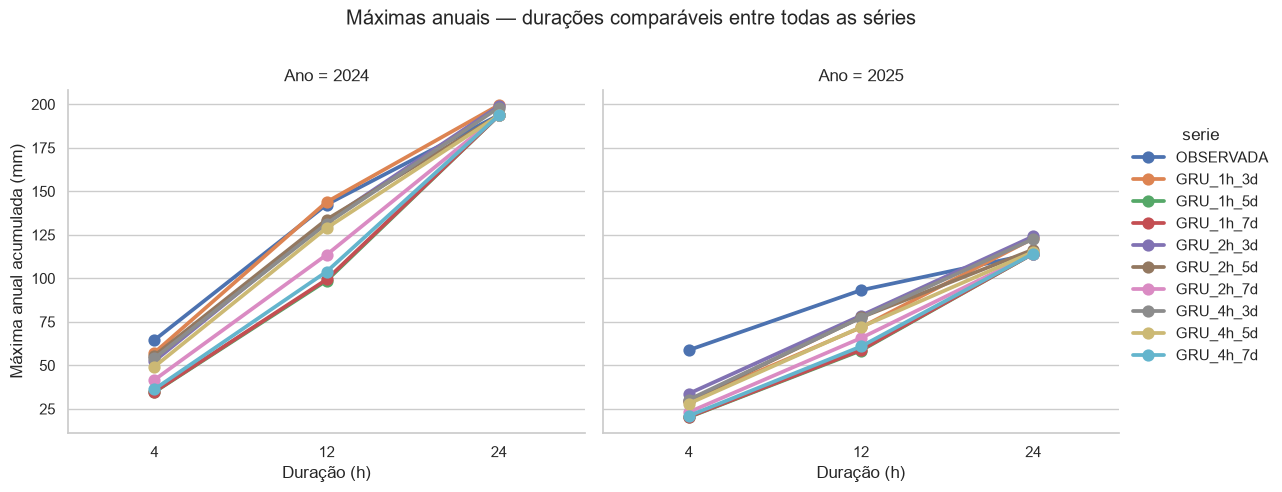

In [10]:
base_larga = maximos.copy()
base_larga["janela_dias"] = (
    base_larga["janela_dias"].astype("Int64").astype("string").fillna("observada")
)
tabela_larga = base_larga.pivot(
    index=["serie", "tipo", "resolucao_h", "janela_dias", "ano"],
    columns="duracao_h",
    values="maximo_acumulado_mm",
).reset_index()
tabela_larga.columns.name = None
tabela_larga = tabela_larga.rename(columns={d: f"max_{d}h_mm" for d in DURACOES_HORAS})
display(tabela_larga)

plot_df = comuns.dropna(subset=["maximo_acumulado_mm"])
g = sns.catplot(
    data=plot_df,
    x="duracao_h", y="maximo_acumulado_mm", hue="serie",
    col="ano", kind="point", height=5, aspect=1.15,
)
g.set_axis_labels("Duração (h)", "Máxima anual acumulada (mm)")
g.set_titles("Ano = {col_name}")
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle("Máximas anuais — durações comparáveis entre todas as séries")
plt.show()

## 7. Exportação dos CSVs

In [11]:
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

arq_completo = PASTA_SAIDA / "maximos_anuais_2024_2025_completo.csv"
arq_comuns = PASTA_SAIDA / "maximos_anuais_2024_2025_comuns_4h_12h_24h.csv"
arq_comparacao = PASTA_SAIDA / "comparacao_modelos_observado_por_resolucao.csv"
arq_larga = PASTA_SAIDA / "maximos_anuais_2024_2025_tabela_larga.csv"
arq_inventario = PASTA_SAIDA / "inventario_series.csv"

maximos.to_csv(arq_completo, index=False, date_format="%Y-%m-%d %H:%M:%S")
comuns.to_csv(arq_comuns, index=False, date_format="%Y-%m-%d %H:%M:%S")
comparacao.to_csv(arq_comparacao, index=False, date_format="%Y-%m-%d %H:%M:%S")
tabela_larga.to_csv(arq_larga, index=False)
inventario.to_csv(arq_inventario, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("Arquivos criados:")
for caminho in [arq_completo, arq_comuns, arq_comparacao, arq_larga, arq_inventario]:
    print(" -", caminho.resolve())

Arquivos criados:
 - B:\Codigos\DesgracaoChuvas\resultados_maximos_anuais\maximos_anuais_2024_2025_completo.csv
 - B:\Codigos\DesgracaoChuvas\resultados_maximos_anuais\maximos_anuais_2024_2025_comuns_4h_12h_24h.csv
 - B:\Codigos\DesgracaoChuvas\resultados_maximos_anuais\comparacao_modelos_observado_por_resolucao.csv
 - B:\Codigos\DesgracaoChuvas\resultados_maximos_anuais\maximos_anuais_2024_2025_tabela_larga.csv
 - B:\Codigos\DesgracaoChuvas\resultados_maximos_anuais\inventario_series.csv


## Como interpretar os arquivos

- **`maximos_anuais_2024_2025_completo.csv`**: todas as máximas que cada resolução permite. A série de 1 h possui 1, 2, 4, 6, 12 e 24 h; a de 2 h possui 2, 4, 6, 12 e 24 h; a de 4 h possui 4, 12 e 24 h.
- **`maximos_anuais_2024_2025_comuns_4h_12h_24h.csv`**: somente 4, 12 e 24 h, permitindo comparar conjuntamente as dez séries.
- **`comparacao_modelos_observado_por_resolucao.csv`**: uma linha por modelo, ano e duração compatível, acrescentando o máximo observado e os erros absoluto e relativo.
- **`maximos_anuais_2024_2025_tabela_larga.csv`**: uma linha por série e ano, com uma coluna para cada duração.

Como o teste contém apenas 2024 e 2025, esses resultados servem para avaliar a reprodução dos eventos extremos desses anos. Dois anos não são suficientes para ajustar com segurança uma distribuição de frequência ou uma curva IDF completa.